In [1]:
! pip3 install --user "pymongo"

In [2]:
import pymongo as pm
from pprint import pprint
import datetime
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
client = pm.MongoClient(
    'bigdatadb.polito.it',
    ssl=True,
    authSource='carsharing',
    username='ictts',
    password='Ict4SM22!',
    tlsAllowInvalidCertificates=True
)

In [4]:
db = client['carsharing']
pb_coll = db['PermanentBookings']
ab_coll = db['ActiveBookings']
pp_coll = db['PermanentParkings']
ap_coll = db['ActiveParkings']

In [121]:
#Step 1 : Preliminary data analysis

In [122]:
# How much data are present in each collection
# pb : 28 180 508
ab_coll.count_documents({})

8743

In [123]:
pp_coll.count_documents({})

28312676

In [124]:
# pp : 28312676
ap_coll.count_documents({})

4790

In [125]:
'''
Why the number of documents in PermanentParkings and PermanentBooking is similar?
'''
# at each booking you have a new parking slot at the end -> so add a period on both coll The slight differrence is due to caveats

'\nWhy the number of documents in PermanentParkings and PermanentBooking is similar?\n'

In [126]:
'''
For which cities the system is collecting data?
'''
# liste des actives plus courte
pb_coll.distinct("city")

['Amsterdam',
 'Austin',
 'Berlin',
 'Calgary',
 'Columbus',
 'Denver',
 'Firenze',
 'Frankfurt',
 'Hamburg',
 'Madrid',
 'Milano',
 'Montreal',
 'Munchen',
 'New York City',
 'Portland',
 'Rheinland',
 'Roma',
 'San Diego',
 'Seattle',
 'Stuttgart',
 'Torino',
 'Toronto',
 'Twin Cities',
 'Vancouver',
 'Washington DC',
 'Wien']

In [127]:
ab_coll.distinct("city")

['Amsterdam',
 'Austin',
 'Berlin',
 'Calgary',
 'Columbus',
 'Denver',
 'Firenze',
 'Frankfurt',
 'Hamburg',
 'Madrid',
 'Milano',
 'Montreal',
 'Munchen',
 'New York City',
 'Portland',
 'Rheinland',
 'Roma',
 'Seattle',
 'Stuttgart',
 'Torino',
 'Toronto',
 'Vancouver',
 'Washington DC',
 'Wien']

In [12]:
'''
When did each collection start? When did each collection end?
'''
res = pb_coll.find({},{'init_time':1,'_id':0}).sort("init_time", 1).limit(1)

In [13]:
list(res)
#2016-12-13 (unix traduction) et pour ab 2018-01-24

[{'init_time': 1481650703}]

In [14]:
res1 = pb_coll.find({},{'final_time':1,'_id':0}).sort("init_time", -1).limit(1)

In [15]:
list(res1)
#2018-01-31 et pour ab -1 (tjrs en cours)

[{'final_time': 1517404383}]

In [16]:
res2 = pp_coll.find({},{'init_time':1,'_id':0}).sort("init_time", 1).limit(1)

In [17]:
list(res2)
# same

[{'init_time': 1481650658}]

In [18]:
res3 = pp_coll.find({},{'final_time':1,'_id':0}).sort("init_time", -1).limit(1)

In [19]:
list(res3)
# same

[{'final_time': 1517404383}]

In [20]:
'''
What about the time zone of the init_date and init_time timestamps? Which time zone do they refer to?
'''
# UNIX = UTC+0 
# Offset : Torino : +1 : UNIX + 1*3600
# Offset : Columbus : -5 : UNIX - 5*3600
# Offset : Frankfurt : +1UNIX + 1*3600

'\nWhat about the time zone of the init_date and init_time timestamps? Which time zone do they refer to?\n'

In [21]:
"""
What is the total number of cars seen in the whole period in each city? How can you estimate the
fleet size in a given period, e.g., one week? How does this relate to the total number of vehicles seen
in the whole collection?
"""
res4=pb_coll.distinct("plate", {"city": "Torino"})

In [22]:
print(len(res4))

609


In [23]:
res5=pb_coll.distinct("plate", {"city": "Frankfurt"})

In [24]:
print(len(res5))

304


In [25]:
res6=pb_coll.distinct("plate", {"city": "Columbus"})

In [26]:
print(len(res6))

215


In [129]:
Init_Time = res = pb_coll.find({},{'init_time':1,'_id':0}).sort("init_time", 1).limit(1)
Final_Time = pb_coll.find({},{'final_time':1,'_id':0}).sort("init_time", -1).limit(1)

Init_Time = next(Init_Time)['init_time']
Final_Time = next(Final_Time)['final_time']

print(Init_Time, Final_Time)

1481650703 1517404383


In [130]:
pipeline = [
    {
        "$match": {
            "city": "Torino",
            "init_time": {
                "$gte": Init_Time,
                "$lte": Final_Time
            }
        }
    },
    {
        "$group": {
            "_id": {
                "week": {
                    "$dateTrunc": {
                        "date": {
                            "$toDate": {
                                "$multiply": ["$init_time", 1000]
                            }
                        },
                        "unit": "week",
                        "startOfWeek": "monday"
                    }
                },
                "plate": "$plate"
            }
        }
    },
    {
        "$group": {
            "_id": "$_id.week",
            "nb_plates": {"$sum": 1}
        }
    },
    {
        "$sort": {
            "_id": 1
        }
    }
]

weekly = list(pb_coll.aggregate(pipeline))

In [131]:
df = pd.DataFrame(weekly)

df.rename(columns={
    "_id": "week",
    "nb_plates": "unique_plates"
}, inplace=True)

df

,week,unique_plates
0,2016-12-12,394
1,2016-12-19,393
2,2016-12-26,395
3,2017-01-02,390
4,2017-01-09,395
5,2017-01-16,399
6,2017-01-23,398
7,2017-01-30,393
8,2017-02-06,396
9,2017-02-13,394


Nombre moyen de voitures par semaine à Turin : 391.23


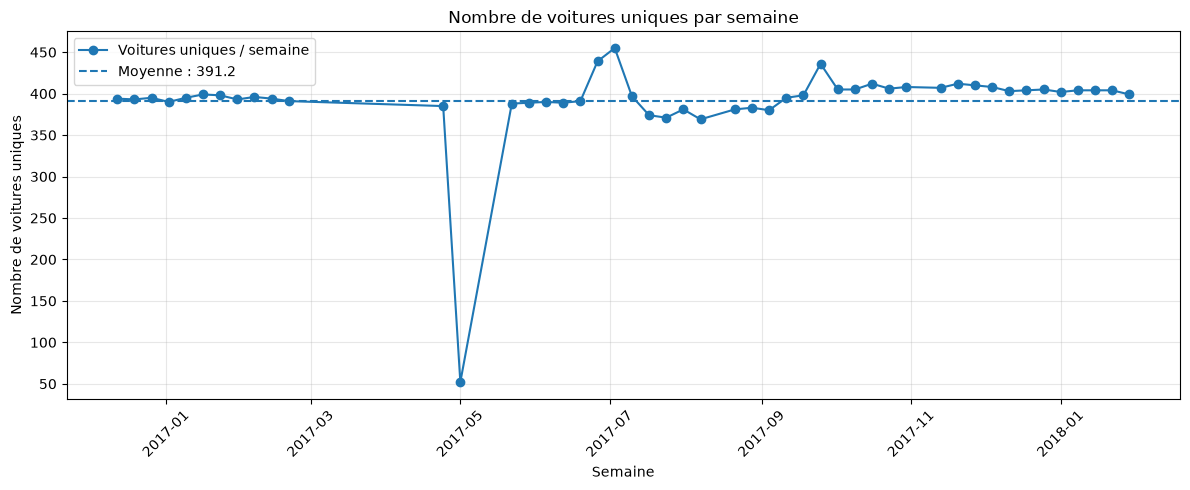

In [132]:
import matplotlib.pyplot as plt

# Moyenne du nombre de voitures uniques par semaine
mean_cars = df["unique_plates"].mean()

print(f"Nombre moyen de voitures par semaine à Turin : {mean_cars:.2f}")

# Graphique
plt.figure(figsize=(12, 5))

plt.plot(
    df["week"],
    df["unique_plates"],
    marker="o",
    label="Voitures uniques / semaine"
)

plt.axhline(
    mean_cars,
    linestyle="--",
    label=f"Moyenne : {mean_cars:.1f}"
)

plt.xlabel("Semaine")
plt.ylabel("Nombre de voitures uniques")
plt.title("Nombre de voitures uniques par semaine")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

In [133]:
# How many bookings have been recorded in December 2017 in each city?
# = ok if begin time is in december

# Offset : Torino : +1 : UNIX + 1*3600
# Offset : Columbus : -5 : UNIX - 5*3600
# Offset : Frankfurt : +1UNIX + 1*3600

pb_turino_dec = pb_coll.count_documents({
    'city': 'Torino',
    'init_date': {
        '$gte': datetime.datetime(2017, 11, 30, 23, 0, 0),
        '$lt': datetime.datetime(2017, 12, 31, 23, 0, 0)
    }
})
pb_turino_dec

96038

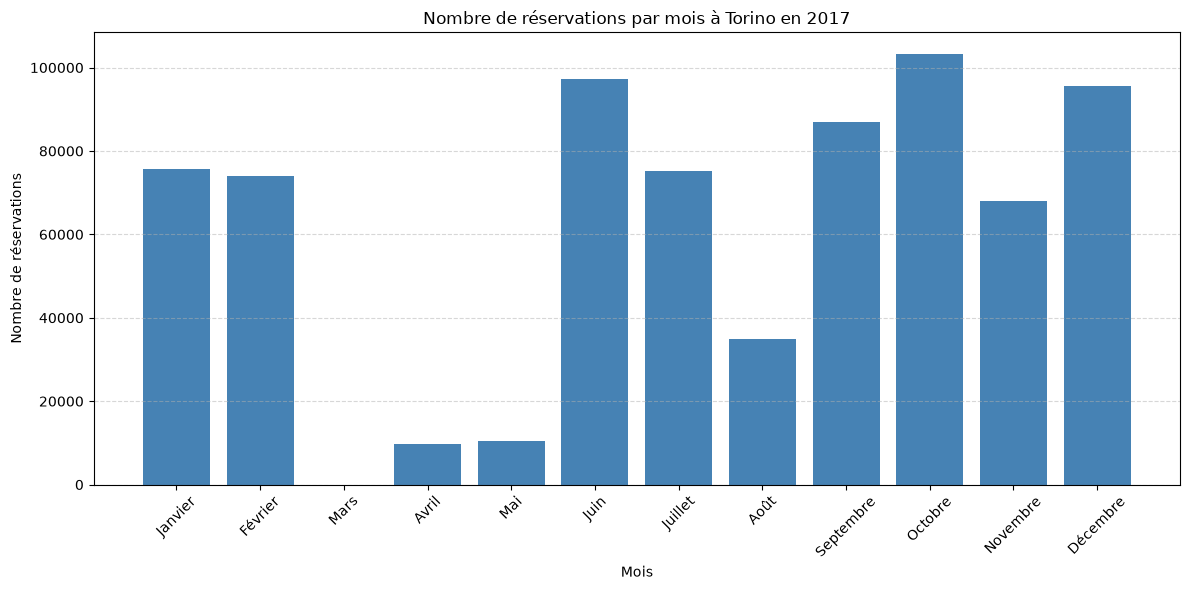

In [134]:
import pandas as pd
import matplotlib.pyplot as plt

# Nombre de réservations par mois pour Torino en 2017
resa_par_mois = []

for mois in range(1, 13):
    date_debut = datetime.datetime(2017, mois, 1, 1, 0, 0)

    if mois == 12:
        date_fin = datetime.datetime(2018, 1, 1, 1, 0, 0)
    else:
        date_fin = datetime.datetime(2017, mois + 1, 1, 1, 0, 0)

    nb_resa = pb_coll.count_documents({
        'city': 'Torino',
        'init_date': {
            '$gte': date_debut,
            '$lt': date_fin
        }
    })

    resa_par_mois.append(nb_resa)

# Affichage du graphique
mois_labels = [
    'Janvier', 'Février', 'Mars', 'Avril', 'Mai', 'Juin',
    'Juillet', 'Août', 'Septembre', 'Octobre', 'Novembre', 'Décembre'
]

plt.figure(figsize=(12, 6))
plt.bar(mois_labels, resa_par_mois, color='steelblue')

plt.title('Nombre de réservations par mois à Torino en 2017')
plt.xlabel('Mois')
plt.ylabel('Nombre de réservations')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [135]:
pb_frankfurt_dec = pb_coll.count_documents({
    'city': 'Frankfurt',
    'init_date': {
        '$gte': datetime.datetime(2017, 11, 30, 23, 0, 0),
        '$lt': datetime.datetime(2017, 12, 31, 23, 0, 0)
}})
pb_frankfurt_dec

53960

In [136]:
pb_columbus_dec = pb_coll.count_documents({
    'city': 'Columbus',
    'init_date': {
        '$gte': datetime.datetime(2017, 12, 1, 5, 0, 0), 
        '$lt': datetime.datetime(2018, 1, 1, 5, 0, 0)
    }
})
pb_columbus_dec

20769

In [94]:
# How many bookings have the alternative transportation modes recorded in each city?

pb_altmode_torino = pb_coll.count_documents({
    'city': 'Torino',
    'public_transport.duration': {'$ne': -1},
    'public_transport.distance': {'$ne': -1},
    'public_transport.distance': {'$ne': 0},
    'public_transport.arrival_date': {'$ne': -1},
    'public_transport.arrival_time': {'$ne': -1}
})
pb_altmode_torino

261629

In [ ]:
pb_altmode_torino = pb_coll.count_documents({
    'city': 'Torino',
    'public_transport.duration': {'$ne': -1},
    'public_transport.distance': {'$ne': -1},
    'public_transport.arrival_date': {'$ne': -1},
    'public_transport.arrival_time': {'$ne': -1}
})
pb_altmode_torino

In [ ]:
pb_altmode_torino = pb_coll.count_documents({
    'city': 'Torino',
    'public_transport.duration': {'$ne': -1},
    'public_transport.distance': {'$ne': -1}
})
pb_altmode_torino

In [ ]:
pb_altmode_torino = pb_coll.count_documents({
    'city': 'Torino',
    'public_transport.duration': {'$ne': -1},
    'public_transport.distance': {'$ne': -1},
    'public_transport.distance': {'$ne': 0}
})
pb_altmode_torino

In [ ]:
pb_altmode_frankfurt = pb_coll.count_documents({
    'city': 'Frankfurt',
    'public_transport.duration': {'$ne': -1},
    'public_transport.distance': {'$ne': -1},
    'public_transport.distance': {'$ne': 0},
    'public_transport.arrival_date': {'$ne': -1},
    'public_transport.arrival_time': {'$ne': -1}
})
pb_altmode_frankfurt

In [ ]:
pb_altmode_columbus = pb_coll.count_documents({
    'city': 'Columbus',
    'public_transport.duration': {'$ne': -1},
    'public_transport.distance': {'$ne': -1},
    'public_transport.distance': {'$ne': 0},
    'public_transport.arrival_date': {'$ne': -1},
    'public_transport.arrival_time': {'$ne': -1}
})
pb_altmode_columbus

In [ ]:
## Step 2 – Car sharing usage characterization
"""
Consider each city of your group, and the period of time of November 1st 2017 – January 31st 2018.
Consider the time series (city, timestamp, duration, locations). Process it to further analyse it by producing
the following plots and results.
"""

In [96]:
"""pb_timeseries = pb_coll.aggregate([
    {
        '$project': {
            '_id': 0,
            'city': 1,
            'init_date': 1,
            'final_date': 1,
            'init_address': 1,
            'final_address': 1,
            'origin_destination': 1,
            'duration': {
                '$subtract': ['$final_time', '$init_time']
            }
        }
    }
])

pb_timeseries_df = pd.DataFrame(list(pb_timeseries))
pb_timeseries_df.head(10).plot(
    x='city',
    y='duration',
    kind='bar',
    figsize=(10, 5)
)

plt.show()"""

"pb_timeseries = pb_coll.aggregate([\n    {\n        '$project': {\n            '_id': 0,\n            'city': 1,\n            'init_date': 1,\n            'final_date': 1,\n            'init_address': 1,\n            'final_address': 1,\n            'origin_destination': 1,\n            'duration': {\n                '$subtract': ['$final_time', '$init_time']\n            }\n        }\n    }\n])\n\npb_timeseries_df = pd.DataFrame(list(pb_timeseries))\npb_timeseries_df.head(10).plot(\n    x='city',\n    y='duration',\n    kind='bar',\n    figsize=(10, 5)\n)\n\nplt.show()"

In [97]:
# Q1 Adam

In [98]:
# Q2: Consider the system utilization over time: 
# aggregate rentals per hour of the day, and then plot the number of booked/parked cars (or percentage of booked/parked cars) per hour versus time of day.
# Do you notice any outliers? Can you explain them?

# V1 : We count a rental on all the hour time slot it appears 
# V2 : We count a rental only on the hour it begins in 

In [10]:
def avg_systutilization(coll, city):

    start_ts = datetime.datetime(2017, 11, 1, 0, 0, 0)
    end_ts = datetime.datetime(2018, 2, 1, 0, 0, 0)

    df = pd.DataFrame(list(coll.find(
        {'city': city,
         "init_date": {
             "$gte": start_ts,
             "$lt": end_ts
         }},
        {
            '_id': 0,
            'init_date': 1,
            'final_date': 1
        }
    )))

    if df.empty:
        print("No data available for this city and period.")
        return

    # Générer les heures de la série temporelle
    hours = pd.date_range(
        df['init_date'].min().floor('h'),
        df['final_date'].max().floor('h'),
        freq='h'
    )

    # V1 : nombre de locations actives à chaque heure
    hourly_rentals_v1 = pd.Series({
        hour: (
            (df['init_date'] < hour + pd.Timedelta(hours=1)) &
            (df['final_date'] > hour)
        ).sum()
        for hour in hours
    })

    # Regrouper par heure de la journée (0 à 23)
    hourly_profile_v1 = hourly_rentals_v1.groupby(
        hourly_rentals_v1.index.hour
    ).mean().reindex(range(24), fill_value=0)

    # Tracer le graphique
    hourly_profile_v1.plot(
        kind='bar',
        figsize=(12, 5),
        rot=0
    )

    plt.xlabel('Hour of day')
    plt.ylabel('Average number of active rentals')
    plt.title(f'Average system utilization by hour — {city}')
    plt.xticks(range(24))
    plt.grid(axis='y')
    plt.show()

    return hourly_profile_v1

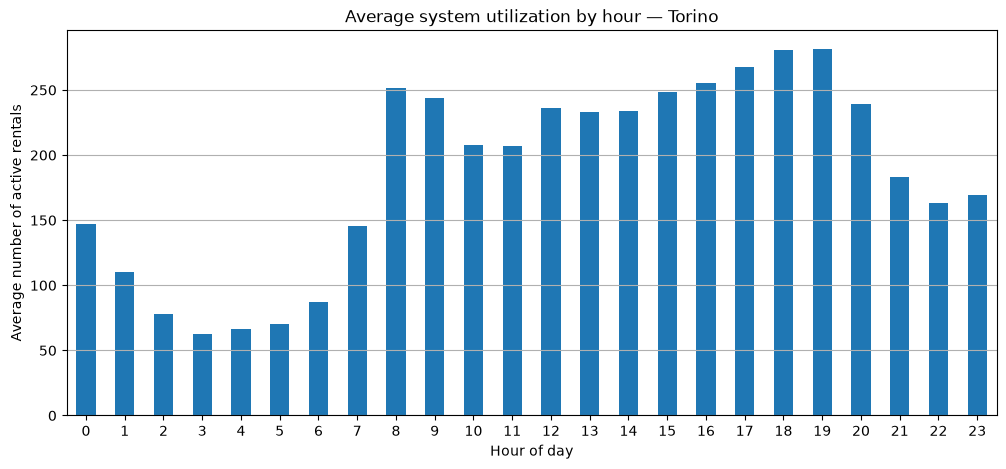

0     146.804348
1     110.119565
2      78.239130
3      62.467391
4      66.445652
5      69.989130
6      87.336957
7     145.239130
8     251.315217
9     243.989130
10    207.967391
11    206.956522
12    235.989130
13    232.913043
14    233.858696
15    248.186813
16    255.010989
17    267.725275
18    280.780220
19    281.626374
20    239.395604
21    182.890110
22    163.329670
23    169.000000
dtype: float64

In [11]:
avg_systutilization(pb_coll,'Torino')

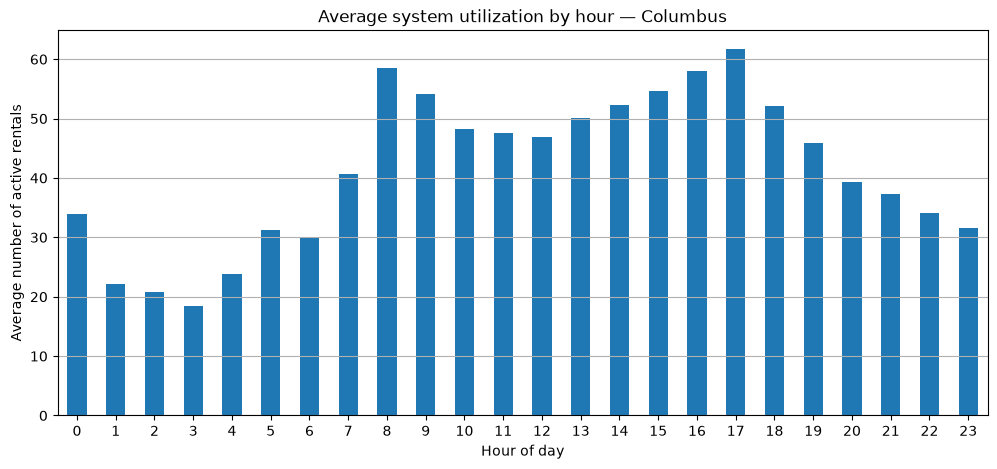

0     33.869565
1     22.108696
2     20.750000
3     18.489130
4     23.793478
5     31.184783
6     30.000000
7     40.641304
8     58.543478
9     54.120879
10    48.296703
11    47.571429
12    46.846154
13    50.131868
14    52.351648
15    54.692308
16    57.945055
17    61.747253
18    52.186813
19    45.945055
20    39.296703
21    37.230769
22    34.076923
23    31.604396
dtype: float64

In [12]:
avg_systutilization(pb_coll,'Columbus')

In [13]:
def avg_parking_start(coll,city):

    start_ts = datetime.datetime(2017, 11, 1, 0, 0, 0)
    end_ts = datetime.datetime(2018, 2, 1, 0, 0, 0)

    df = pd.DataFrame(list(coll.find(
        {'city': city,
         "init_date": {
             "$gte": start_ts,
             "$lt": end_ts
         }},
        {
            '_id': 0,
            'init_date': 1
        }
    )))

    # Extraire le jour et l'heure de chaque location
    df['day'] = df['init_date'].dt.date
    df['hour'] = df['init_date'].dt.hour
    
    # Compter les locations pour chaque jour et chaque heure
    rentals_per_day_hour = (
        df.groupby(['day', 'hour'])
          .size()
          .rename('rentals')
          .reset_index()
    )
    
    # Calculer la moyenne par heure sur l'ensemble des jours
    hourly_rentals_v2 = (
        rentals_per_day_hour.groupby('hour')['rentals']
        .mean()
        .reindex(range(24), fill_value=0)
    )
    
    # Tracer le graphique
    hourly_rentals_v2.plot(
        kind='bar',
        figsize=(12, 5),
        rot=0
    )
    
    plt.xlabel('Hour of day')
    plt.ylabel('Average number of rentals started')
    plt.title(f'Average rental starts by hour of day — {city}')
    plt.xticks(range(24))
    plt.grid(axis='y')
    plt.show()

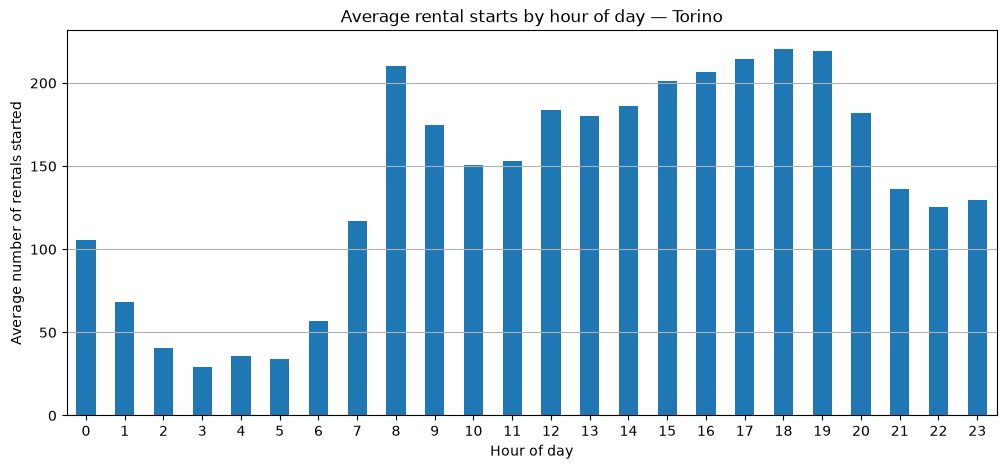

In [14]:
avg_parking_start(pb_coll,"Torino")

In [15]:
def avg_permanentparking(coll,city):

    start_ts = datetime.datetime(2017, 11, 1, 0, 0, 0)
    end_ts = datetime.datetime(2018, 2, 1, 0, 0, 0)

    df = pd.DataFrame(list(coll.find(
        {'city': city,
         "init_date": {
             "$gte": start_ts,
             "$lt": end_ts
         }},
        {
            '_id': 0,
            'init_date': 1,
            'final_date': 1
        }
    )))
    
    # Générer les heures de la série temporelle
    hours = pd.date_range(
        df['init_date'].min().floor('h'),
        df['final_date'].max().floor('h'),
        freq='h'
    )
    
    # V1 : nombre de locations actives à chaque heure
    hourly_rentals_v1 = pd.Series({
        hour: (
            (df['init_date'] < hour + pd.Timedelta(hours=1)) &
            (df['final_date'] > hour)
        ).sum()
        for hour in hours
    })
    
    # Regrouper par heure de la journée (0 à 23)
    hourly_profile_v1 = hourly_rentals_v1.groupby(
        hourly_rentals_v1.index.hour
    ).mean().reindex(range(24), fill_value=0)
    
    # Tracer le graphique
    hourly_profile_v1.plot(
        kind='bar',
        figsize=(12, 5),
        rot=0
    )
    
    plt.xlabel('Hour of day')
    plt.ylabel('Average number of permanent parking')
    plt.title(f'{city}')
    plt.xticks(range(24))
    plt.grid(axis='y')
    plt.show()

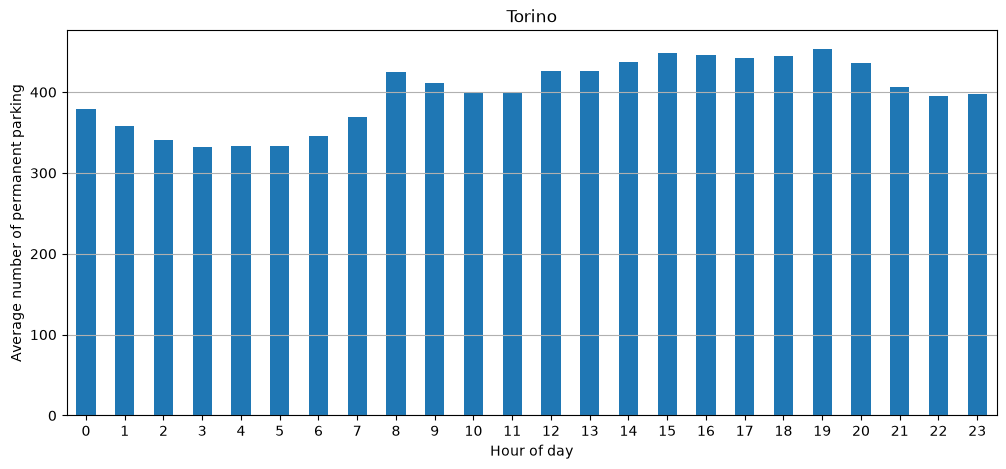

In [16]:
avg_permanentparking(pp_coll,"Torino")

In [20]:
def avg_parking_start(coll,city):
    if city == 'Columbus':
        start, end = start_Col, end_Col
    else:
        start, end = start_ToFr, end_ToFr

    start_ts = int(start.timestamp())
    end_ts = int(end.timestamp())

    df = pd.DataFrame(list(coll.find(
        {'city': city,
        "init_time": {
                    "$gte": start_ts,
                    "$lte": end_ts
                }},
        {
            '_id': 0,
            'init_date': 1,
        }
    )))

    
    # Extraire le jour et l'heure de chaque location
    df['day'] = df['init_date'].dt.date
    df['hour'] = df['init_date'].dt.hour
    
    # Compter les locations pour chaque jour et chaque heure
    rentals_per_day_hour = (
        df.groupby(['day', 'hour'])
          .size()
          .rename('rentals')
          .reset_index()
    )
    
    # Calculer la moyenne par heure sur l'ensemble des jours
    hourly_rentals_v2 = (
        rentals_per_day_hour.groupby('hour')['rentals']
        .mean()
        .reindex(range(24), fill_value=0)
    )
    
    # Tracer le graphique
    hourly_rentals_v2.plot(
        kind='bar',
        figsize=(12, 5),
        rot=0
    )
    
    plt.xlabel('Hour of day')
    plt.ylabel('Average number of parking started')
    plt.title(f'Average parking starts by hour of day in {city}')
    plt.xticks(range(24))
    plt.grid(axis='y')
    plt.show()

In [21]:
avg_parking_start(pp_coll,"Torino")

NameError: name 'start_ToFr' is not defined

In [ ]:
def fleet_utilization_city(coll,city):

    if city == 'Columbus':
        start, end = start_Col, end_Col
    else:
        start, end = start_ToFr, end_ToFr

    start_ts = int(start.timestamp())
    end_ts = int(end.timestamp())

    df = pd.DataFrame(list(coll.find(
        {'city': city,
        "init_time": {
                    "$gte": start_ts,
                    "$lte": end_ts
                }},
        {
            '_id': 0,
            'init_date': 1,
            'final_date': 1,
            'plate': 1
        }
    )))
    
    # Convertir les dates
    df['init_date'] = pd.to_datetime(df['init_date'])
    df['final_date'] = pd.to_datetime(df['final_date'])
    
    # Garder les locations valides
    df = df.dropna(subset=['init_date', 'final_date'])
    df = df[df['final_date'] > df['init_date']].copy()
    
    if df.empty:
        raise ValueError("Aucune location valide trouvée pour Torino.")
    
    # Nombre de voitures distinctes observées dans pb_coll
    total_cars = df.loc[
        df['plate'].notna() & (df['plate'] != -1),
        'plate'
    ].nunique()
    
    if total_cars == 0:
        raise ValueError("Aucune plaque valide trouvée dans les données.")
    
    # Créer les créneaux horaires
    hours = pd.date_range(
        df['init_date'].min().floor('h'),
        df['final_date'].max().ceil('h'),
        freq='h',
        inclusive='left'
    )
    
    # V1 : une location compte dans chaque heure qu'elle chevauche
    hourly_rentals = pd.Series({
        hour: (
            (df['init_date'] < hour + pd.Timedelta(hours=1)) &
            (df['final_date'] > hour)
        ).sum()
        for hour in hours
    })
    
    # Moyenne par heure de la journée sur tous les jours observés
    hourly_avg = (
        hourly_rentals.groupby(hourly_rentals.index.hour)
        .mean()
        .reindex(range(24), fill_value=0)
    )
    
    # Pourcentage approximatif de voitures occupées
    utilization_pct = hourly_avg / total_cars * 100
    
    print("Nombre de locations valides :", len(df))
    print("Nombre de voitures distinctes observées :", total_cars)
    print("Valeurs manquantes :", utilization_pct.isna().sum())
    print("Valeurs infinies :", np.isinf(utilization_pct).sum())
    print(utilization_pct.round(2))
    
    # Tracer
    utilization_pct.plot(
        kind='bar',
        figsize=(12, 5),
        rot=0
    )
    
    plt.xlabel('Hour of day')
    plt.ylabel('Booked cars (%)')
    plt.title(f'Average fleet utilization by hour — {city}')
    plt.xticks(range(24))
    plt.grid(axis='y')
    plt.tight_layout()
    plt.show()


In [ ]:
fleet_utilization_city(pb_coll,"Torino")

In [ ]:
fleet_utilization_city(pb_coll,"Columbus")

In [ ]:
fleet_utilization_city(pb_coll,"Frankfurt")

In [ ]:
"""
Expliquer pk on utilise pb_coll pour ce résultat

Des pics le matin et en fin d'après-midi peuvent correspondre aux déplacements domicile-travail.
Un taux d'utilisation très élevé peut indiquer une forte demande.
Des pics isolés peuvent être dus à des événements particuliers ou à des anomalies dans les données.


--> Est ce que toutes les voitures sont résa ? Tjrs les mêmes ? Dans quelles zones ? Vers quelles zones ? + Regarder et comparer avec nombre de voiture présent dans la ville
Peut être sympa de comparer avec l'autre marque de voiture en loc 
"""

In [ ]:
#Q3 Adam

In [ ]:
#Q4 : Filtering data as above, consider the system utilization over time. How do they change compared to
# the unfiltered versions? Are you able to filter outliers efficiently for both bookings and parkings?
# Consider also to plot the CDF of the filtered events. How do these compare to the unfiltered versions?

In [ ]:
# Recup Adam
# load : prends une collection et une ville et fais une dataframe filtrée
# 
from AdamsNB.ipynb import load, plot_cdf_wo_outlier

